<a href="https://colab.research.google.com/github/emmanresu/Thesis-Keras/blob/latest%2Funstable/ML_pipeline_notebook_version.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data preparation, Engineering, and Initializations

### Import Dependencies

In [ ]:
pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 28.1 MB/s eta 0:00:00


In [ ]:
import pandas as pd
from pandas.plotting import lag_plot
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

from joblib import dump, load

from datetime import datetime
from sklearn.model_selection import TimeSeriesSplit

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score

import pmdarima as pm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing

from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from xgboost import plot_importance

np.set_printoptions(legacy='1.25')

### Helper functions

In [ ]:
# Adds an "is_lean_month" column to indicate if a period is in lean month or not

def add_lean_months(dataset):
  lean = set([7, 8, 9])
  dataset.index = pd.to_datetime(dataset['date']).dt.to_period('M')
  dataset['is_lean_month'] = np.where(dataset.index.month.isin(lean), 1, 0)
  dataset.reset_index(inplace=True, drop=True)
  return dataset

In [ ]:
# Shift features n months,
# returns 2 objects [1: data for training and testing | 2: data for forecasting]
# Param 1 -> dataset
# Param 2 -> column excluded (dependent variable/what we need to predict)
# Param 3 -> number of months to shift
# Param 4 -> number of months for object 2 [data for forecasting]

def shift_all_features(data, target, months_shift, test):
  if "is_lean_month" in data.columns:
    data_shift = data.drop(columns=["is_lean_month"])
  if target in data.columns:
    data_shift = data.drop(columns=[target])

  data_shift.index = pd.to_datetime(data['date']).dt.to_period('M')
  data_shift = data_shift.drop(columns=['date'])

  data_shift = data_shift.shift(periods=months_shift, freq="infer")
  stock_total = data[['date', target]]
  stock_total.index = pd.to_datetime(stock_total['date']).dt.to_period('M')
  # stock_total = stock_total.drop(columns=['date'])

  data_shift = pd.concat([stock_total, data_shift], axis=1)

  data_shift = data_shift[months_shift:]

  data_shift['date'] = data_shift.index

  data_shift, remaining_features = data_shift[0:-test], data_shift[-test:]

  data_shift.reset_index(drop=True, inplace=True)
  remaining_features.reset_index(drop=True, inplace=True)

  return data_shift, remaining_features

In [ ]:
# display a correlation heatmap
def show_correlation(data):
  corr_matrix = data.corr()

  # Create the plot
  plt.figure(figsize=(6,  4))
  sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
  plt.title('Correlation Heatmap')
  # plt.show('correlation_plot.png')
  # print("correlation_plot.png saved")

In [ ]:
def evaluate_model(test, predictions, title):
  mape = mean_absolute_percentage_error(test, predictions)
  mae = mean_absolute_error(test, predictions)
  rmse = root_mean_squared_error(test, predictions)
  r2 = r2_score(test, predictions)

  print(f"{title} Model MAPE {round(mape, 4)}\n"
  f"{title} Model MAE: {round(mae, 4)}\n"
  f"{title} Model RMSE: {round(rmse, 4)}\n"
  f"{title} Model R2: {round(r2, 4)}")

### Load dataset

In [ ]:
data = pd.read_csv("dataset.csv")

### Add lean months

In [ ]:
data = add_lean_months(data)

### Shift features to 24 months


In [ ]:
dataset, remaining_features = shift_all_features(data, 'total_stock', 24, 24)

### Split dataset train and test

In [ ]:
holdout_size = 24                       #
data_train = dataset[0:-holdout_size]   # data validation is also included in data_train
data_test = dataset[-holdout_size:]     # latest data should be the test data since we are doing a
                                        #     time series forecast/ prediction

## SARIMA model

In [ ]:
# 1. Automatically determine 'd' and 'D' using ADF and other tests
d_order = pm.arima.ndiffs(data_train["total_stock"], test='adf')          # test = 'adf' working
D_order = pm.arima.nsdiffs(data_train["total_stock"], m=12, test='ocsb')  # test = 'ocsb' working

print(f"Recommended non-seasonal differencing (d): {d_order}")
print(f"Recommended seasonal differencing (D): {D_order}")

# 2. Fit the SARIMA model using those parameters
# Example order: (p, d, q) x (P, D, Q, s)
sarima = SARIMAX(data_train["total_stock"],
                order=(0, 1, 0),                # order=(1, d_order, 1),
                seasonal_order=(0, 1, 1, 12))   # seasonal_order=(1, D_order, 1, 12)

sarima_model = sarima.fit()
print(sarima_model.summary())

Recommended non-seasonal differencing (d): 0
Recommended seasonal differencing (D): 0
                                      SARIMAX Results                                       
Dep. Variable:                          total_stock   No. Observations:                  271
Model:             SARIMAX(0, 1, 0)x(0, 1, [1], 12)   Log Likelihood               -3499.343
Date:                              Sat, 19 Sep 2026   AIC                           7002.686
Time:                                      14:54:24   BIC                           7009.792
Sample:                                           0   HQIC                          7005.543
                                              - 271                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.S.L12    

In [ ]:
sarima_forecast = sarima_model.forecast(steps=holdout_size)
sarima_forecast

,predicted_mean
271,1.899914e+06
272,1.773290e+06
273,2.313865e+06
274,2.503134e+06
275,2.407591e+06
276,2.253044e+06
277,1.823718e+06
278,1.703466e+06
279,2.206506e+06
280,2.343770e+06


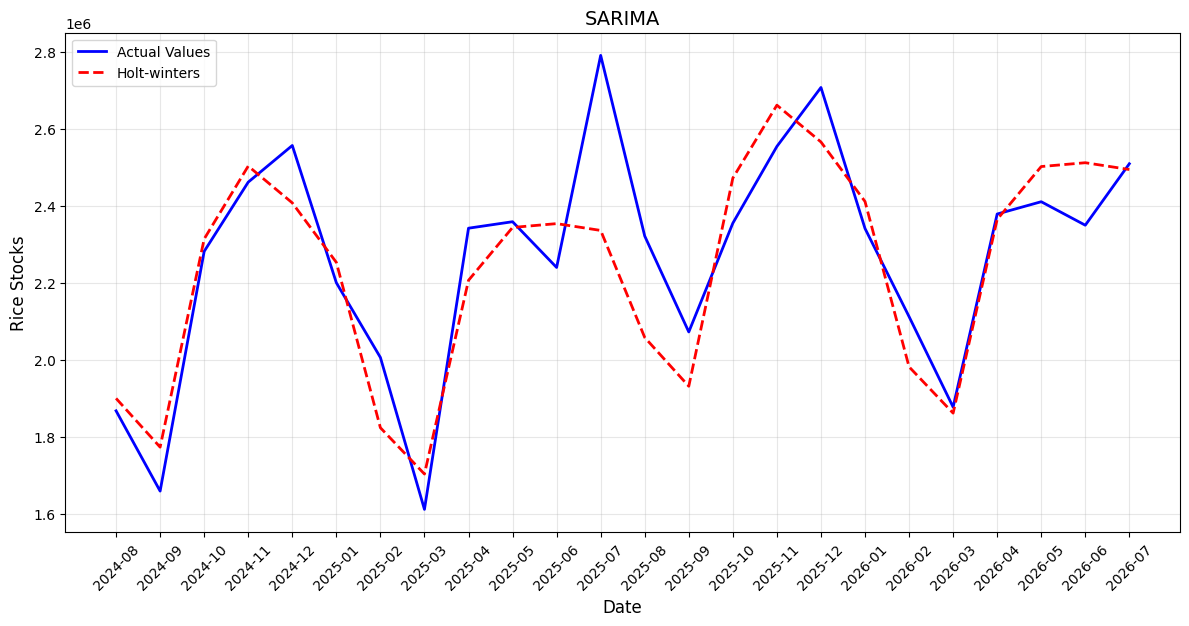

In [ ]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], data_test['total_stock'], label=f'Actual Values', color='blue', linewidth=2)

# Predicted Values
plt.plot(data['date'].iloc[-holdout_size:], sarima_forecast, label=f'Holt-winters', color='red', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('SARIMA', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [ ]:
evaluate_model(data_test['total_stock'], sarima_forecast, "SARIMA")

SARIMA Model MAPE 0.0487
SARIMA Model MAE: 111822.3126
SARIMA Model RMSE: 146247.6212
SARIMA Model R2: 0.7491


## Holt-Winters model

In [ ]:
def tscv_holt_winters(data, seasonal_periods, param_grid, splits, train_each_fold):
    tscv = TimeSeriesSplit(n_splits=splits, max_train_size=train_each_fold)

    # Generate all combinations of alpha, beta, and gamma
    keys, values = zip(*param_grid.items())
    combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

    results_list = []

    for combo in combinations:
        fold_mapes = []
        fold_mae = []
        fold_rmse = []
        fold_r2 = []
        train_size = []
        test_size = []

        # Cross-validation on the train_val subset
        for train_index, test_index in tscv.split(train_val):
            train, test = train_val.iloc[train_index], train_val.iloc[test_index]

            try:
                model = ExponentialSmoothing(
                    train,
                    trend='add',
                    seasonal='add',
                    seasonal_periods=seasonal_periods
                ).fit(
                    smoothing_level=combo['alpha'],
                    smoothing_trend=combo['beta'],
                    smoothing_seasonal=combo['gamma'],
                    optimized=False
                )

                forecast = model.forecast(len(test))
                mape = mean_absolute_percentage_error(test, forecast)
                mae = mean_absolute_error(test, forecast)
                rmse = root_mean_squared_error(test, forecast)
                r2 = r2_score(test, forecast)

                fold_mae.append(mae)
                fold_rmse.append(rmse)
                fold_mapes.append(mape)
                fold_r2.append(r2)

                train_input = len(train)
                train_size.append(train_input)
                test_input = len(test)
                test_size.append(test_input)
            except Exception:
                # Handle cases where parameters lead to non-convergence
                continue

        # Store average performance and parameters for the list
        if fold_mapes:
            avg_mape = np.mean(fold_mapes)
            avg_mae = np.mean(fold_mae)
            avg_rmse = np.mean(fold_rmse)
            avg_r2 = np.mean(fold_r2)
            mape_variance = np.var(fold_mapes)
            results_list.append({
                "alpha": combo['alpha'],
                "beta": combo['beta'],
                "gamma": combo['gamma'],
                "mape_variance" : round(mape_variance, 8),
                "avg_MAPE": round((avg_mape), 4),
                "avg_MAE": round((avg_mae), 4),
                "avg_RMSE": round((avg_rmse), 4),
                "avg_R2": round((avg_r2), 4),
                "fold_details": [(tr_size, ts_size, round(mape, 4))
                  for tr_size, ts_size, mape in zip(train_size, test_size, fold_mapes)]
            })
    # return sorted(results_list, key=lambda x: x['mape_variance'])
    return results_list

In [ ]:
# parameters to be tested
params = {
  'alpha': [0.1, 0.3, 0.5, 0.7, 0.9],
  'beta': [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9],
  'gamma': [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
}

In [ ]:
''''
tscv_holt_winters(1, 2, 3, 4, 5) parameters:
  1 - training set
  2 - number of seasonal period - 12(yearly) default
  3 - hyperparameters (grid)
  4 - number of folds (number of cross-validation)
  5 - number of maximum training set (set to None for expanding window approach)
'''
train_val = data_train["total_stock"]
models_exp = tscv_holt_winters(train_val, 12, params, 5, None)

In [ ]:
avg_mape_models = sorted(models_exp, key=lambda x: x['avg_MAPE'])

top_lowest_mape = [x for x in avg_mape_models[:10]]
for i in top_lowest_mape:
  print(i)

{'alpha': 0.1, 'beta': 0.3, 'gamma': 0.9, 'mape_variance': 0.00246585, 'avg_MAPE': 0.1969, 'avg_MAE': 448530.8836, 'avg_RMSE': 554767.0514, 'avg_R2': -0.3639, 'fold_details': [(46, 45, 0.1151), (91, 45, 0.2149), (136, 45, 0.2676), (181, 45, 0.1815), (226, 45, 0.2052)]}
{'alpha': 0.1, 'beta': 0.5, 'gamma': 0.7, 'mape_variance': 0.00966118, 'avg_MAPE': 0.1974, 'avg_MAE': 462374.7563, 'avg_RMSE': 576061.3624, 'avg_R2': -0.774, 'fold_details': [(46, 45, 0.1714), (91, 45, 0.1854), (136, 45, 0.138), (181, 45, 0.3862), (226, 45, 0.1061)]}
{'alpha': 0.1, 'beta': 0.3, 'gamma': 0.7, 'mape_variance': 0.00544207, 'avg_MAPE': 0.1998, 'avg_MAE': 448013.423, 'avg_RMSE': 577519.5679, 'avg_R2': -0.5509, 'fold_details': [(46, 45, 0.1148), (91, 45, 0.3314), (136, 45, 0.1755), (181, 45, 0.2189), (226, 45, 0.1585)]}
{'alpha': 0.3, 'beta': 0.01, 'gamma': 0.7, 'mape_variance': 0.00551481, 'avg_MAPE': 0.2131, 'avg_MAE': 443443.6841, 'avg_RMSE': 532197.1087, 'avg_R2': -0.4189, 'fold_details': [(46, 45, 0.1562)

In [ ]:
''' The parameters with the lowest average mape / mape variance across all folds is selected
for the final model.  '''

best_model_onavg = top_lowest_mape[0]
print(f"Best Parameters: level: {best_model_onavg['alpha']} | "
      f"trend: {best_model_onavg['beta']} | seasonal: {best_model_onavg['gamma']}")

# 3. Prepare the Final Datasets
train_val = data_train["total_stock"]
test = data_test["total_stock"]

# 4. Train the Final Model on the entire train_val set
hw_model = ExponentialSmoothing(
    train_val,
    trend='add',
    seasonal='add',
    seasonal_periods=12,
).fit(
    smoothing_level=best_model_onavg['alpha'],
    smoothing_trend=best_model_onavg['beta'],
    smoothing_seasonal=best_model_onavg['gamma'],
    optimized=False
)

Best Parameters: level: 0.1 | trend: 0.3 | seasonal: 0.9


In [ ]:
hw_forecast = hw_model.forecast(holdout_size)
hw_forecast

,0
271,1.821264e+06
272,1.802718e+06
273,2.348100e+06
274,2.416480e+06
275,2.441026e+06
276,2.593417e+06
277,2.098700e+06
278,1.969291e+06
279,2.468765e+06
280,2.681307e+06


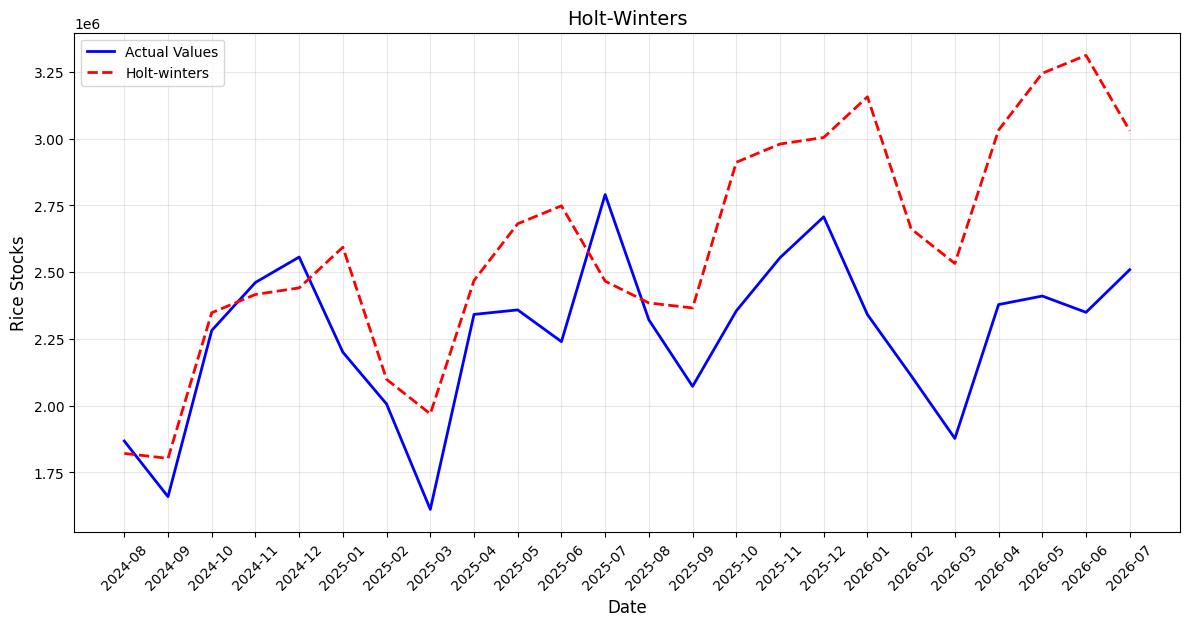

In [ ]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], data_test['total_stock'], label=f'Actual Values', color='blue', linewidth=2)

# Predicted Values
plt.plot(data['date'].iloc[-holdout_size:], hw_forecast, label=f'Holt-winters', color='red', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('Holt-Winters', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [ ]:
evaluate_model(data_test['total_stock'], hw_forecast, "Holt-Winters")

Holt-Winters Model MAPE 0.1692
Holt-Winters Model MAE: 382061.0072
Holt-Winters Model RMSE: 465609.0627
Holt-Winters Model R2: -1.5429


## XGBoost Model Standalone

In [ ]:
xgb_reg = XGBRegressor(objective='reg:squarederror', random_state=42,
                       enable_categorical=True, early_stopping=True)

In [ ]:
param_grid = {
    'n_estimators': [10, 50, 100, 300, 500, 700],
    'max_depth': [2, 3, 5, 7],
    'learning_rate': [0.001, 0.01, 0.05, 0.1], # [0.001, 0.01, 0.05, 0.1]
    'subsample:': [0.2, 0.4],
    'min_child_weight': [3, 5, 7],
    'colsample_bytree': [0.5, 0.8],
    # 'gamma': [0.5, 1],
    'reg_lambda': [0.1, 0.5, 1, 2, 3]
}

In [ ]:
grid_search = GridSearchCV(
    estimator=xgb_reg,
    param_grid=param_grid,
    # cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_mean_absolute_error', # 'neg_mean_squared_error', 'r2'
    refit=True,
    n_jobs=-1,
)

In [ ]:
validation_size = 24

In [ ]:
X_train = data_train[:-validation_size].drop(columns=["date", "total_stock"])
y_train = data_train[:-validation_size]["total_stock"]
X_val = data_train[-validation_size:].drop(columns=["date", "total_stock"])
y_val = data_train[-validation_size:]["total_stock"]

In [ ]:
grid_search.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:07:08] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


GridSearchCV(estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping=True,
                                    early_stopping_rounds=None,
                                    enable_categorical=True, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_co...
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.5, 0.8],
                         'learning_rate': [0.001, 0.01, 0.05, 0.1],
                         'max_depth': [2, 3, 5, 7],
                         'min_child_weight': [3, 5, 7],
                         'n_estimators': [10, 50, 100, 300, 500, 700],
                         'reg_lambda': [0.1, 0.5, 1, 2, 3],
                         'subsample:': [0.2, 0.4]},
             scoring='neg_mean_absolute_error')

In [ ]:
dump(grid_search, 'xgb_gridsearch.pkl')

In [ ]:
grid_search_xgb = load('xgb_gridsearch.pkl')

In [ ]:
xgb_model = grid_search_xgb.best_estimator_
xgb_forecast = xgb_model.predict(data_test.drop(columns=["date", "total_stock"]))

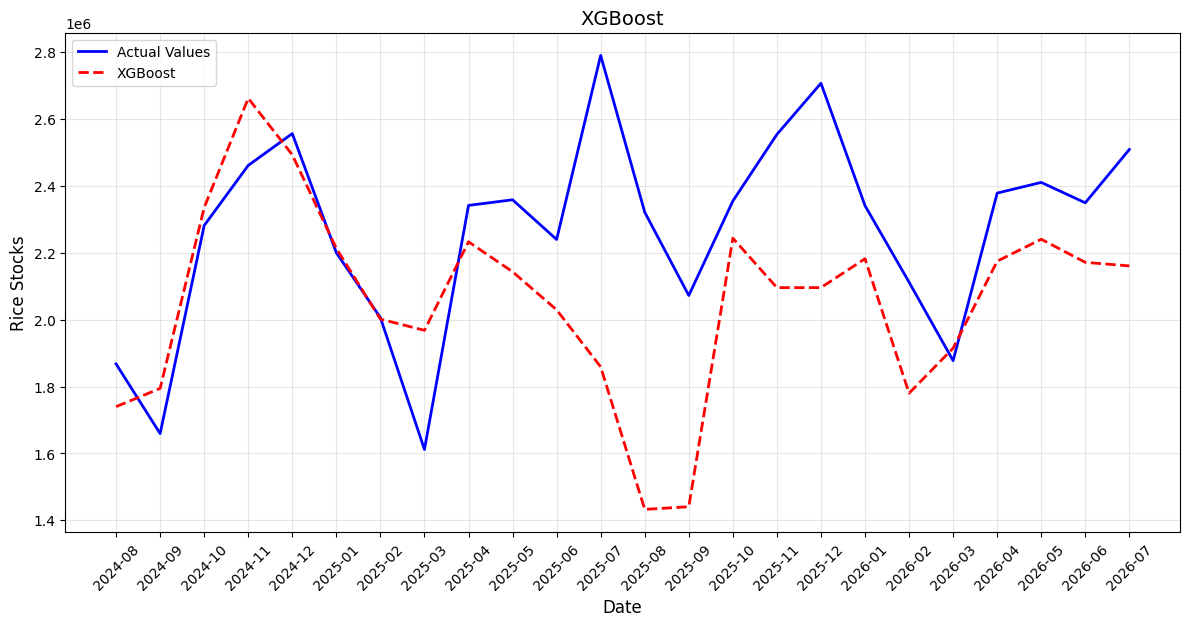

In [ ]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], data_test['total_stock'], label=f'Actual Values', color='blue', linewidth=2)

# Predicted Values
plt.plot(data['date'].iloc[-holdout_size:], xgb_forecast, label=f'XGBoost', color='red', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('XGBoost', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [ ]:
evaluate_model(xgb_forecast, data_test["total_stock"], "XGBoost")

XGBoost Model MAPE 0.1469
XGBoost Model MAE: 272959.8306
XGBoost Model RMSE: 372236.8566
XGBoost Model R2: -0.7417


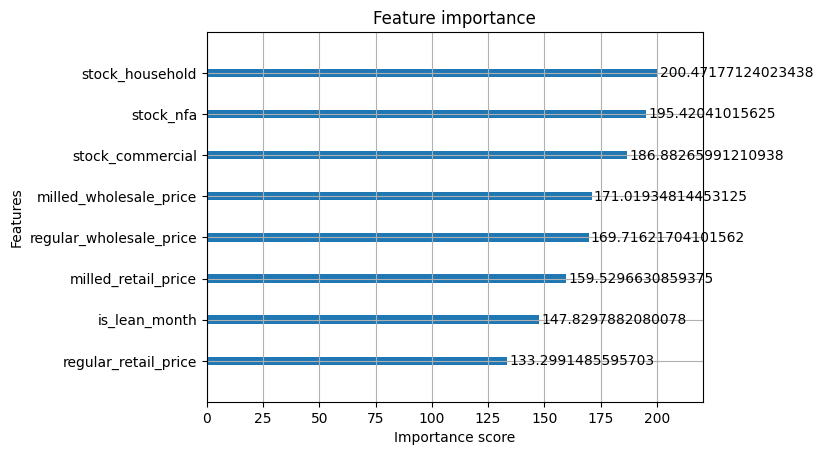

In [ ]:
plot_importance(xgb_model, importance_type='cover')
plt.show()

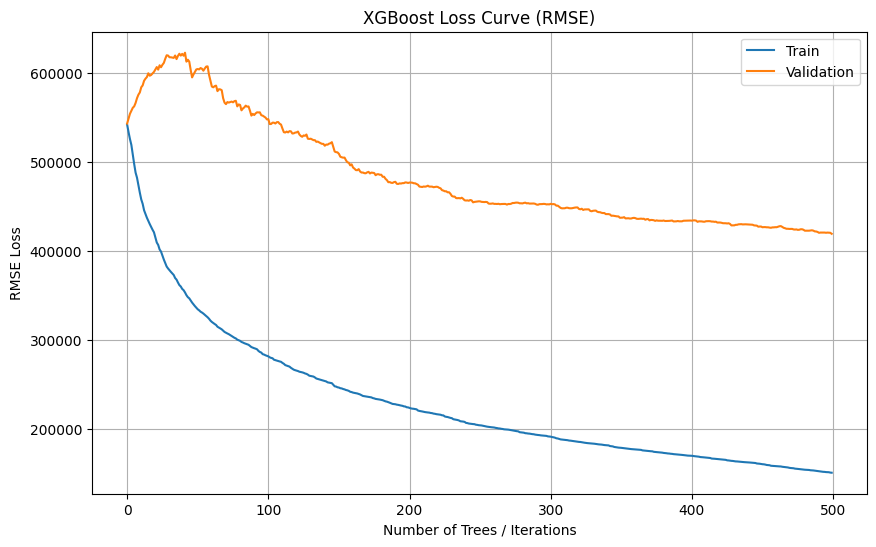

In [ ]:
results = xgb_model.evals_result()

epochs = len(results['validation_0']['rmse'])
x_axis = range(0, epochs)

# 4. Plot the loss curves
plt.figure(figsize=(10, 6))
plt.plot(x_axis, results['validation_0']['rmse'], label='Train')
plt.plot(x_axis, results['validation_1']['rmse'], label='Validation')

plt.title('XGBoost Loss Curve (RMSE)')
plt.xlabel('Number of Trees / Iterations')
plt.ylabel('RMSE Loss')
plt.legend()
plt.grid(True)
plt.show()

## Hybrid model - HW + XGBoost

In [ ]:
hybrid_dataset = data_train

In [ ]:
hybrid_dataset["residuals"] = hybrid_dataset["total_stock"] - hw_model.fittedvalues
hybrid_dataset = hybrid_dataset.drop(columns=["total_stock"])

/tmp/ipykernel_1319/3523522585.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hybrid_dataset["residuals"] = hybrid_dataset["total_stock"] - hw_model.fittedvalues


In [ ]:
data_train_hybrid = hybrid_dataset[0:-holdout_size]
data_test_hybrid = hybrid_dataset[-holdout_size:]

In [ ]:
X_train_hybrid = data_train_hybrid[:-validation_size].drop(columns=["residuals", "date"])
y_train_hybrid = data_train_hybrid[:-validation_size]["residuals"]
X_val_hybrid = data_train_hybrid[-validation_size:].drop(columns=["residuals", "date"])
y_val_hybrid = data_train_hybrid[-validation_size:]["residuals"]

In [ ]:
grid_search.fit(
    X_train_hybrid, y_train_hybrid,
    eval_set=[(X_train_hybrid, y_train_hybrid), (X_val_hybrid, y_val_hybrid)],
    verbose=False
)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [04:29:47] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


GridSearchCV(estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping=True,
                                    early_stopping_rounds=None,
                                    enable_categorical=True, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_co...
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.5, 0.8],
                         'learning_rate': [0.001, 0.01, 0.05, 0.1],
                         'max_depth': [2, 3, 5, 7],
                         'min_child_weight': [3, 5, 7],
                         'n_estimators': [10, 50, 100, 300, 500, 700],
                         'reg_lambda': [0.1, 0.5, 1, 2, 3],
                         'subsample:': [0.2, 0.4]},
             scoring='neg_mean_absolute_error')

In [ ]:
dump(grid_search, 'hybrid_gridsearch.pkl')

In [ ]:
grid_search_hybrid = load('hybrid_gridsearch.pkl')

In [ ]:
hybrid_model = grid_search_hybrid.best_estimator_

In [ ]:
hybrid_forecast = hybrid_model.predict(data_test_hybrid.drop(columns=["date", "residuals"]))

In [ ]:
hw_xgb_forecast = hw_forecast + hybrid_forecast

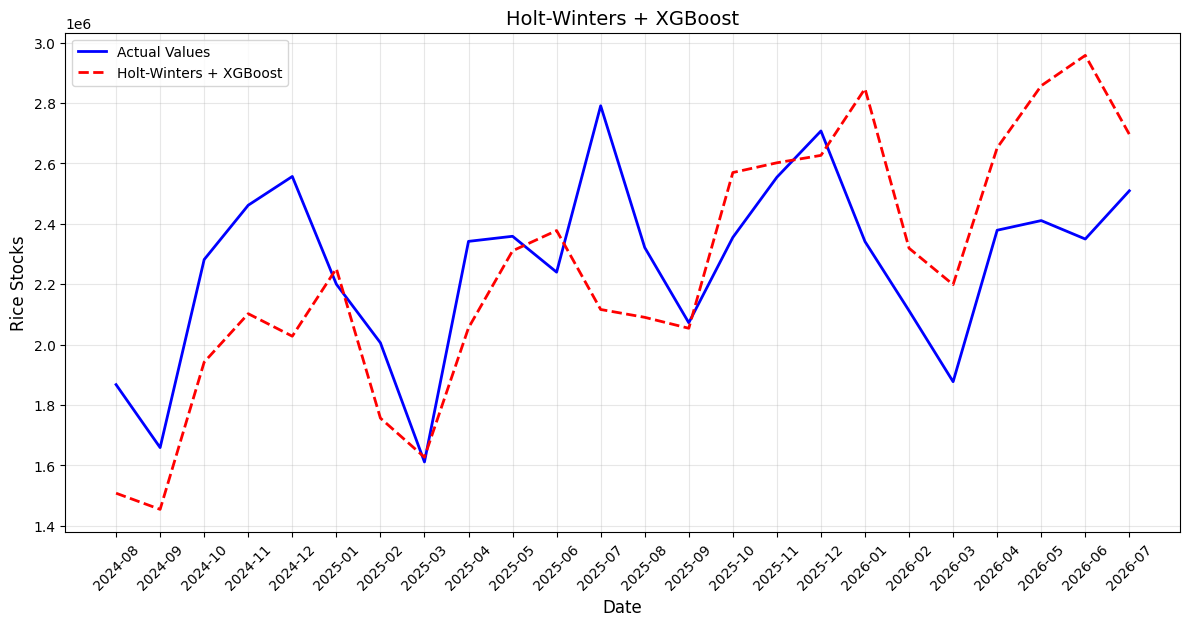

In [ ]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], data_test['total_stock'], label=f'Actual Values', color='blue', linewidth=2)

# Predicted Values
plt.plot(data['date'].iloc[-holdout_size:], hw_xgb_forecast, label=f'Holt-Winters + XGBoost', color='red', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('Holt-Winters + XGBoost', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [ ]:
evaluate_model(data_test["total_stock"], hw_xgb_forecast, "Holt-Winters + XGBoost")

Holt-Winters + XGBoost Model MAPE 0.1161
Holt-Winters + XGBoost Model MAE: 266434.7939
Holt-Winters + XGBoost Model RMSE: 323149.148
Holt-Winters + XGBoost Model R2: -0.2249


## Models comparison

In [ ]:
test = data_test["total_stock"]

sarima_mape = mean_absolute_percentage_error(test, sarima_forecast)
sarima_mae = mean_absolute_error(test, sarima_forecast)
sarima_rmse = root_mean_squared_error(test, sarima_forecast)
sarima_r2 = r2_score(test, sarima_forecast)

hw_mape = mean_absolute_percentage_error(test, hw_forecast)
hw_mae = mean_absolute_error(test, hw_forecast)
hw_rmse = root_mean_squared_error(test, hw_forecast)
hw_r2 = r2_score(test, hw_forecast)

xgb_mape = mean_absolute_percentage_error(test, xgb_forecast)
xgb_mae = mean_absolute_error(test, xgb_forecast)
xgb_rmse = root_mean_squared_error(test, xgb_forecast)
xgb_r2 = r2_score(test, xgb_forecast)

hybrid_mape = mean_absolute_percentage_error(test, hw_xgb_forecast)
hybrid_mae = mean_absolute_error(test, hw_xgb_forecast)
hybrid_rmse = root_mean_squared_error(test, hw_xgb_forecast)
hybrid_r2 = r2_score(test, hw_xgb_forecast)

In [ ]:
metrics_dict = {
    "MAPE": [sarima_mape, hw_mape, xgb_mape, hybrid_mape],
    "MAE": [sarima_mae, hw_mae, xgb_mae, hybrid_mae],
    "RMSE": [sarima_rmse, hw_rmse, xgb_rmse, hybrid_rmse],
    "R2": [sarima_r2, hw_r2, xgb_r2, hybrid_r2]
}

models = ["Sarima", "Holt-Winters", "XGBoost standalone", "Holt-Winters and XGBoost"]

# Display as a DataFrame
metrics_df = pd.DataFrame(metrics_dict, models)
print(metrics_df)

                              MAPE            MAE           RMSE        R2
Sarima                    0.048722  111822.312551  146247.621197  0.749117
Holt-Winters              0.169242  382061.007164  465609.062661 -1.542939
XGBoost standalone        0.117946  272959.830625  372236.856576 -0.625294
Holt-Winters and XGBoost  0.116106  266434.793934  323149.148005 -0.224896


## Further Experiments

### One rice price only (regular wholesale price)

In [80]:
data_train_exp = dataset.drop(columns=["milled_wholesale_price",
                                       "regular_retail_price",
                                       "milled_retail_price"])

In [81]:
data_test_exp = dataset.drop(columns=["milled_wholesale_price",
                                      "regular_retail_price",
                                      "milled_retail_price"])

In [82]:
data_train_exp

,date,total_stock,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,is_lean_month
0,2002-01,2270700.00,1149700.00,488200.00,726600.0,15.65,0.0
1,2002-02,1975200.00,1009500.00,420600.00,612200.0,15.83,0.0
2,2002-03,1808200.00,832200.00,381000.00,552500.0,15.98,0.0
3,2002-04,1997200.00,954400.00,441200.00,479300.0,16.05,0.0
4,2002-05,2113200.00,1059500.00,509600.00,497900.0,16.29,0.0
...,...,...,...,...,...,...,...
290,2026-03,1877328.88,694618.06,630285.38,41285.0,47.49,0.0
291,2026-04,2378655.18,938011.79,876590.00,41559.0,47.09,0.0
292,2026-05,2410587.01,863765.39,1142655.42,69350.0,47.00,0.0
293,2026-06,2349596.02,696547.07,1328853.71,138273.0,46.71,0.0


In [83]:
X_train_exp = data_train_exp[:-validation_size].drop(columns=["date", "total_stock"])
y_train_exp = data_train_exp[:-validation_size]["total_stock"]
X_val_exp = data_train_exp[-validation_size:].drop(columns=["date", "total_stock"])
y_val_exp = data_train_exp[-validation_size:]["total_stock"]

In [ ]:
grid_search.fit(
    X_train_exp, y_train_exp,
    eval_set=[(X_train_exp, y_train_exp), (X_val_exp, y_val_exp)],
    verbose=False
)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [07:34:41] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


GridSearchCV(estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping=True,
                                    early_stopping_rounds=None,
                                    enable_categorical=True, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_co...
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.5, 0.8],
                         'learning_rate': [0.001, 0.01, 0.05, 0.1],
                         'max_depth': [2, 3, 5, 7],
                         'min_child_weight': [3, 5, 7],
                         'n_estimators': [10, 50, 100, 300, 500, 700],
                         'reg_lambda': [0.1, 0.5, 1, 2, 3],
                         'subsample:': [0.2, 0.4]},
             scoring='neg_mean_absolute_error')

In [ ]:
dump(grid_search, "exp_gridsearch.pkl")

['exp_gridsearch.pkl']

In [84]:
grid_search_xgb_exp = load('exp_gridsearch.pkl')

In [86]:
xgb_exp_model = grid_search_xgb_exp.best_estimator_
xgb_exp_forecast = xgb_exp_model.predict(data_test_exp.drop(columns=["date", "total_stock"]))

In [88]:
xgb_exp_forecast

array([2294270.2, 2093287.9, 1876052.6, 2120448.2, 2050031.2, 1818063.6,
       1599436.1, 1496128.8, 1516359. , 1743979.1, 2401685.8, 2453097.2,
       2418366.8, 2192408.5, 2051513. , 2287615.8, 2299072.5, 2072123.4,
       1867477.2, 1634965.1, 1587941.2, 1864918. , 2458922.5, 2434587.8,
       2272275. , 2008296.2, 1829237.1, 2115390.8, 2220739.8, 1920442.9,
       1662349.9, 1500649.8, 1500649.8, 1685989.9, 2315892.8, 2421121. ,
       2121929. , 1959065.9, 1792942.6, 1902730.6, 2112223.2, 1921544.2,
       1676372.8, 1518308.2, 1508665. , 1698728.6, 2388749.5, 2483503.8,
       2157472.2, 1910353. , 1810373. , 2222761.2, 2305160. , 2018684.2,
       1916094.6, 1634099.4, 1516359. , 1819853.2, 2451717.8, 2490127.8,
       2233344.5, 2037998.9, 1790543.5, 1837384.1, 1888316.8, 1820479. ,
       1770468.4, 1611756.4, 1522575.8, 1696669.1, 2302609.5, 2454764.8,
       2335618.2, 2087106.2, 1837384.1, 2137984.5, 2322403. , 2150241.8,
       2128293.5, 1873540. , 1743892.9, 1933870.4, 

ValueError: x and y must have same first dimension, but have shapes (24,) and (295,)

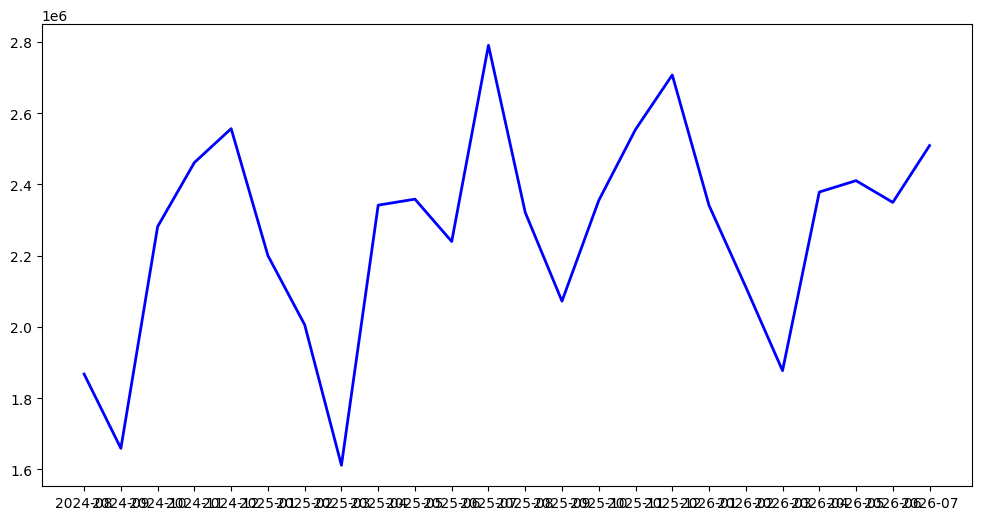

In [87]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], data_test['total_stock'], label=f'Actual Values', color='blue', linewidth=2)

# Predicted Values
plt.plot(data['date'].iloc[-holdout_size:], xgb_exp_forecast, label=f'XGBoost experiment', color='red', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('XGBoost', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [ ]:
evaluate_model(data_test["total_stock"], xgb_exp_forecast, "XGBoost experimental")

XGBoost experimental Model MAPE 0.1179
XGBoost experimental Model MAE: 272959.8306
XGBoost experimental Model RMSE: 372236.8566
XGBoost experimental Model R2: -0.6253


In [ ]:
xgb_exp_mape = mean_absolute_percentage_error(test, xgb_exp_forecast)
xgb_exp_mae = mean_absolute_error(test, xgb_exp_forecast)
xgb_exp_rmse = root_mean_squared_error(test, xgb_exp_forecast)
xgb_exp_r2 = r2_score(test, xgb_exp_forecast)

In [ ]:
metrics_dict = {
    "MAPE": [xgb_mape, xgb_exp_mape],
    "MAE": [xgb_mae, xgb_exp_mae],
    "RMSE": [xgb_rmse, xgb_exp_rmse],
    "R2": [xgb_r2, xgb_exp_r2]
}

models = ["XGBoost standalone", "XGBoost experimental"]

# Display as a DataFrame
metrics_df = pd.DataFrame(metrics_dict, models)
print(metrics_df)

                          MAPE            MAE           RMSE        R2
XGBoost standalone    0.117946  272959.830625  372236.856576 -0.625294
XGBoost experimental  0.117946  272959.830625  372236.856576 -0.625294


### Indian and thai rice prices included

In [ ]:
data_exp2 = pd.read_csv("dataset_experimental.csv")

In [ ]:
data_exp2 = add_lean_months(data_exp2)
dataset_exp2, remaining_features_exp2 = shift_all_features(data_exp2, "total_stock", 24, 24)

In [ ]:
dataset_exp2 = dataset_exp2.drop(columns=["milled_wholesale_price",
                                          "regular_retail_price",
                                          "milled_retail_price"])

In [ ]:
holdout_size = 24
data_train_exp2 = dataset_exp2[0:-holdout_size]
data_test_exp2 = dataset_exp2[-holdout_size:]

In [ ]:
X_train_exp2 = data_train_exp2[:-validation_size].drop(columns=["date", "total_stock"])
y_train_exp2 = data_train_exp2[:-validation_size]["total_stock"]
X_val_exp2 = data_train_exp2[-validation_size:].drop(columns=["date", "total_stock"])
y_val_exp2 = data_train_exp2[-validation_size:]["total_stock"]

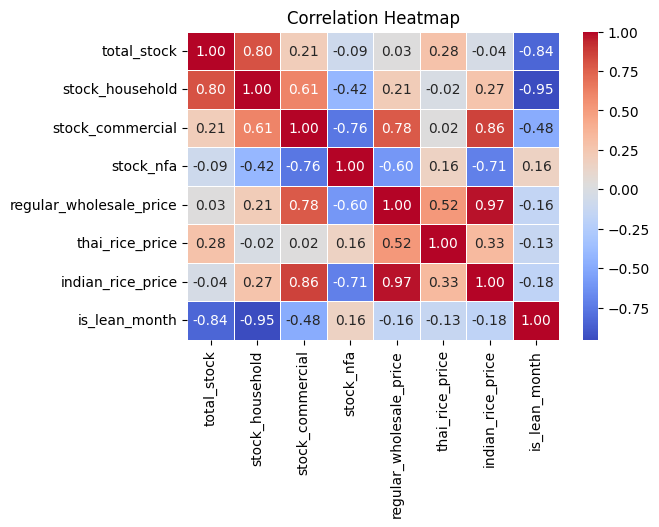

In [ ]:
show_correlation(data_train_exp2.drop(columns=["date"]).corr())

In [70]:
grid_search.fit(
    X_train_exp2, y_train_exp2,
    eval_set=[(X_train_exp2, y_train_exp2), (X_val_exp2, y_val_exp2)],
    verbose=False
)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:26:43] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


GridSearchCV(estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping=True,
                                    early_stopping_rounds=None,
                                    enable_categorical=True, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_co...
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.5, 0.8],
                         'learning_rate': [0.001, 0.01, 0.05, 0.1],
                         'max_depth': [2, 3, 5, 7],
                         'min_child_weight': [3, 5, 7],
                         'n_estimators': [10, 50, 100, 300, 500, 700],
                         'reg_lambda': [0.1, 0.5, 1, 2, 3],
                         'subsample:': [0.2, 0.4]},
             scoring='neg_mean_absolute_error')

In [71]:
dump(grid_search, "exp2_gridsearch.pkl")

['exp2_gridsearch.pkl']

In [72]:
grid_search_xgb_exp2 = load('exp2_gridsearch.pkl')

In [89]:
xgb_exp2_model = grid_search_xgb_exp2.best_estimator_
xgb_exp2_forecast = xgb_exp2_model.predict(data_test_exp2.drop(columns=["date", "total_stock"]))

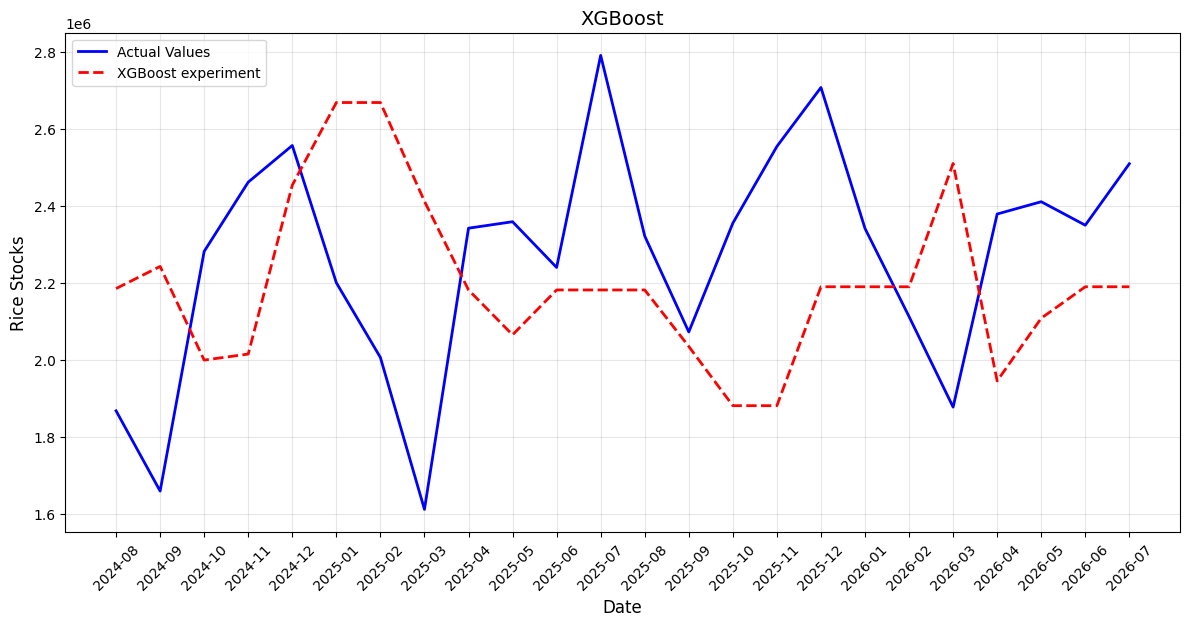

In [90]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], data_test['total_stock'], label=f'Actual Values', color='blue', linewidth=2)

# Predicted Values
plt.plot(data['date'].iloc[-holdout_size:], xgb_exp2_forecast, label=f'XGBoost experiment', color='red', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('XGBoost', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [92]:
evaluate_model(data_test_exp2["total_stock"], xgb_exp2_forecast, "XGBoost experimental 2")

XGBoost experimental 2 Model MAPE 0.1068
XGBoost experimental 2 Model MAE: 237954.9538
XGBoost experimental 2 Model RMSE: 288573.5202
XGBoost experimental 2 Model R2: -0.0062
